## Simulação - Fila com Cadeia de Markov e número de atendentes variável
### SME0123 - Estatística
---
* **Docente:** Eduardo Fontoura Costa
* **Monitor:** Luiz Henrique Romero
* **Alunos:** Pedro Henrique de Sousa Prestes (15507819), João Gabriel Pieroli da Silva (15678578) e Luysa de Souza Gonçalves (15474077)
---

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import random as rd
from scipy.stats import t

In [ ]:
def servidores_estrategia_B(nroClientes):
    """Retorna o número de servidores ativos dependendo do número de clientes x."""
    if nroClientes <= 2:
        return 1
    else:
        return 2

In [ ]:
def simular_fila(estrategia="A", T_final=20.0, lambda_=2.0, mu=2.0):
    """
    Simula a fila M/M/r/4 e retorna (tempos, estados).
    """
    t = 0
    X = 0
    tempos = [0]
    estados = [0]

    while t < T_final:
        # Taxa de chegada
        taxa_chegada = lambda_ if X < 4 else 0

        # Taxa de atendimento
        if estrategia == "A":
            servidores = 1 if X > 0 else 0
        else:
            servidores = servidores_estrategia_B(X)
        taxa_saida = servidores * mu

        # Taxa total
        taxa_total = taxa_chegada + taxa_saida

        # sorteia próximo evento
        delta = np.random.exponential(1 / taxa_total)
        t += delta
        if t > T_final:
            break

        # decide se é chegada ou saída
        if np.random.rand() < taxa_chegada / taxa_total:
            X += 1  # chegada
        else:
            X = max(0, X-1)  # saída

        tempos.append(t)
        estados.append(X)
    return np.array(tempos), np.array(estados)

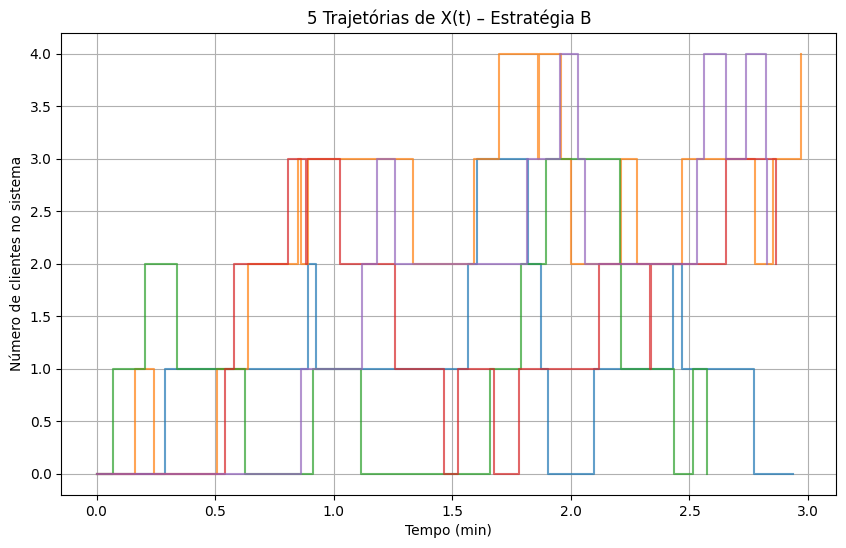

In [ ]:
plt.figure(figsize=(10,6))

for _ in range(5):
    tempos, estados = simular_fila("B", T_final=3)
    plt.step(tempos, estados, where="post", alpha=0.7)

plt.title("5 Trajetórias de X(t) – Estratégia B")
plt.xlabel("Tempo (min)")
plt.ylabel("Número de clientes no sistema")
plt.grid()
plt.show()


Atividade 3 — Teste de Hipótese para X_B(t = 20), N = 40


In [ ]:
def coletar_X_t20(N, estrategia="B"):
    valores = []
    for _ in tqdm(range(N)):
        tempos, estados = simular_fila(estrategia, T_final=20)
        valores.append(estados[-1])
    return np.array(valores)


In [ ]:
def teste_hipotese(valores, mu0=2, alpha=0.01):
    N = len(valores)
    xbar = valores.mean()
    s = valores.std(ddof=1)
    erro = s / np.sqrt(N)

    # estatística t
    t_obs = (xbar - mu0) / erro

    # valor crítico (unilateral, cauda à esquerda)
    t_crit = t.ppf(alpha, df=N-1)

    # Valor limite da média amostral. Se xbar < xc, rejeita-se H0.
    xc = mu0 + (t_crit * erro)

    return {
        "N": N,
        "media": xbar,
        "desvio_amostral": s,
        "erro_padrão": erro,
        "t_obs": t_obs,
        "t_crit": t_crit,
        "xc_valor_critico": xc,
        "rejeita_H0": t_obs < t_crit
    }


In [ ]:
def apresentar_relatorio(res):

    print(f"\n\n{'RELATÓRIO DE TESTE DE HIPÓTESE':^50}")


    print(f"\n1. PARÂMETROS DO TESTE")
    print(f"-"*50)
    print(f" Hipótese Nula (H0):       mu = 2.0")
    print(f" Hipótese Alternativa (H1): mu < 2.0")
    print(f" Nível de Significância:    1% (alpha = 0.01)")
    print(f" Tamanho da Amostra (N):    {res['N']}")

    print(f"\n2. ESTATÍSTICAS DA AMOSTRA")
    print(f"-"*50)
    print(f" Média Observada (X_barra): {res['media']:>10.4f} clientes")
    print(f" Desvio Padrão (s):         {res['desvio_amostral']:>10.4f}")
    print(f" Erro Padrão da Média:      {res['erro_padrão']:>10.4f}")

    print(f"\n3. RESULTADOS DO TESTE t")
    print(f"-"*50)
    print(f" Valor Crítico t (tabela):  {res['t_crit']:>10.4f}")
    print(f" Estatística t (calculado): {res['t_obs']:>10.4f}")
    print(f" Valor Crítico da Média (xc):{res['xc_valor_critico']:>9.4f}") #

    print(f"\n4. CONCLUSÃO")
    print(f"="*50)
    if res['rejeita_H0']:
        decisao = "REJEITAR H0"
        txt = "A Estratégia B reduziu significativamente a média."
    else:
        decisao = "FALHA EM REJEITAR H0"
        txt = "Não há evidência suficiente de melhora."

    print(f" Decisão: {decisao}")
    print(f" Interpretação: {txt}")
    print("="*50)

In [48]:
val40 = coletar_X_t20(40, "B")
resultado_40 = teste_hipotese(val40)
apresentar_relatorio(resultado_40)


100%|██████████| 40/40 [00:00<00:00, 4827.56it/s]



          RELATÓRIO DE TESTE DE HIPÓTESE          

1. PARÂMETROS DO TESTE
--------------------------------------------------
 Hipótese Nula (H0):       mu = 2.0
 Hipótese Alternativa (H1): mu < 2.0
 Nível de Significância:    1% (alpha = 0.01)
 Tamanho da Amostra (N):    40

2. ESTATÍSTICAS DA AMOSTRA
--------------------------------------------------
 Média Observada (X_barra):     1.7250 clientes
 Desvio Padrão (s):             1.3202
 Erro Padrão da Média:          0.2087

3. RESULTADOS DO TESTE t
--------------------------------------------------
 Valor Crítico t (tabela):     -2.4258
 Estatística t (calculado):    -1.3174
 Valor Crítico da Média (xc):   1.4936

4. CONCLUSÃO
 Decisão: FALHA EM REJEITAR H0
 Interpretação: Não há evidência suficiente de melhora.


Atividade 4 — Repetir com N = 1000

In [ ]:
val1000 = coletar_X_t20(1000, "B")
resultado_1000 = teste_hipotese(val1000)
apresentar_relatorio(resultado_1000)


100%|██████████| 1000/1000 [00:00<00:00, 5704.62it/s]



          RELATÓRIO DE TESTE DE HIPÓTESE          

1. PARÂMETROS DO TESTE
--------------------------------------------------
 Hipótese Nula (H0):       mu = 2.0
 Hipótese Alternativa (H1): mu < 2.0
 Nível de Significância:    1% (alpha = 0.01)
 Tamanho da Amostra (N):    1000

2. ESTATÍSTICAS DA AMOSTRA
--------------------------------------------------
 Média Observada (X_barra):     1.4770 clientes
 Desvio Padrão (s):             1.2178
 Erro Padrão da Média:          0.0385

3. RESULTADOS DO TESTE t
--------------------------------------------------
 Valor Crítico t (tabela):     -2.3301
 Estatística t (calculado):   -13.5812
 Valor Crítico da Média (xc):   1.9103

4. CONCLUSÃO
 Decisão: REJEITAR H0
 Interpretação: A Estratégia B reduziu significativamente a média.


Atividade 5 — Tempo Total no Sistema (Variável T)


In [100]:
def simular_tempo_total(estrategia="A", lambda_=2.0, mu=2.0):
    """
    Simula o tempo total T que um cliente passa no sistema em regime.
    """
    # 1. Simula até regime aproximado, desconsiderando casos de fila cheia
    X = 4
    while X == 4:
      tempos, estados = simular_fila(estrategia, T_final=20)
      X = estados[-1]

    # Considera X como o número de pessoas na fila
    X += 1
    minha_posicao = X # Posição do cliente chegou na fila
    tempo_espera = 0

    while minha_posicao > 1:
        taxa_chegada = lambda_ if X < 4 else 0 # Se cheio, ninguém entra

        if estrategia == "A":
            num_servidores = 1
        else:
            num_servidores = servidores_estrategia_B(X)

        taxa_saida = num_servidores * mu
        taxa_total = taxa_chegada + taxa_saida

        dt = np.random.exponential(1 / taxa_total)
        tempo_espera += dt

        if np.random.rand() < (taxa_chegada / taxa_total):
            X += 1
        else:
            X -= 1
            minha_posicao -= 1

    return tempo_espera

In [94]:
def simular_metrica_pdf(estrategia="A", mu=2.0):
    """
    Calcula T usando a simplificação teórica do enunciado (Snapshot).
    Isso deve retornar média ~1.0 para a Estratégia A.
    """
    # 1. Roda a fila até atingir regime (warm-up)
    # Não precisa filtrar X=4 aqui, pois o cálculo teórico do PDF inclui P(4)
    _, estados = simular_fila(estrategia, T_final=50)

    # 2. Tira uma 'foto' do estado atual (Quantas pessoas tem lá?)
    X = estados[-1]

    # 3. Aplica a fórmula do PDF dependendo da estratégia
    if estrategia == "A":
        # Fórmula do PDF: X * (tempo médio de um atendimento)
        # Se X=0 -> 0; Se X=1 -> 0.5; etc.
        tempo_estimado = X * (1/mu)

    else: # Estratégia B
        # Na estratégia B, a velocidade (taxa de saída) depende de X.
        # Se X <= 2, temos 1 servidor (velocidade mu)
        # Se X > 2, temos 2 servidores (velocidade 2*mu)

        if X == 0:
            taxa_atual = mu # Evita divisão por zero, tempo será 0 de qualquer forma
        elif X <= 2:
            taxa_atual = 1 * mu
        else:
            taxa_atual = 2 * mu

        # T = Carga de Trabalho / Velocidade de Saída
        tempo_estimado = X / taxa_atual

    return tempo_estimado

In [95]:
# Coleta 1000 amostras usando a lógica do PDF
amostras_virtuais_A = [simular_metrica_pdf("A") for _ in range(1000)]
amostras_virtuais_B = [simular_metrica_pdf("B") for _ in range(1000)]

print("Média A (Virtual):", np.mean(amostras_virtuais_A))
# Deve dar muito próximo de 1.0

print("Média B (Virtual):", np.mean(amostras_virtuais_B))
# Deve dar um valor menor que a A

Média A (Virtual): 0.99
Média B (Virtual): 0.56625


In [99]:
def coletar_T(N, estrategia="B"):
    return np.array([simular_tempo_total(estrategia) for _ in tqdm(range(N))])

T1000 = coletar_T(1000, "A")
resultado_T1000 = teste_hipotese(T1000, mu0=1)
resultado_T1000

100%|██████████| 1000/1000 [00:00<00:00, 6081.47it/s]


{'N': 1000,
 'media': np.float64(0.7286456821953112),
 'desvio_amostral': np.float64(0.8057119836079509),
 'erro_padrão': np.float64(0.025478850062933746),
 't_obs': np.float64(-10.65017915386421),
 't_crit': np.float64(-2.330086419039454),
 'xc_valor_critico': np.float64(0.9406320774956155),
 'rejeita_H0': np.True_}

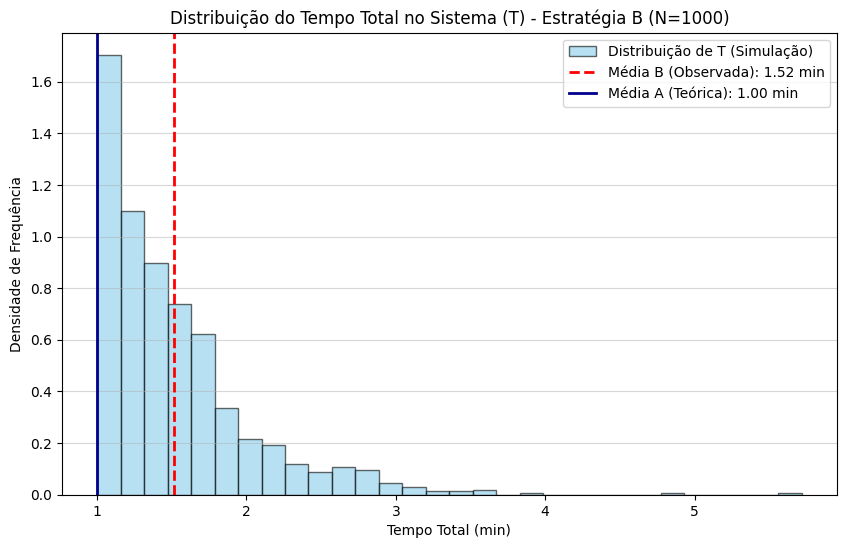

In [64]:
plt.figure(figsize=(10, 6))

plt.hist(T1000, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Distribuição de T (Simulação)')
media_B = np.mean(T1000)
plt.axvline(media_B, color='red', linestyle='--', linewidth=2, label=f'Média B (Observada): {media_B:.2f} min')
plt.axvline(1.0, color='darkblue', linestyle='-', linewidth=2, label='Média A (Teórica): 1.00 min')

plt.title('Distribuição do Tempo Total no Sistema (T) - Estratégia B (N=1000)')
plt.xlabel('Tempo Total (min)')
plt.ylabel('Densidade de Frequência')
plt.legend()
plt.grid(axis='y', alpha=0.5)

plt.show()